In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.sparse as sp
import scipy.sparse.linalg as spla

# Wavelength in micrometers
wavelength = 1.55
k0 = 2 * np.pi / wavelength

# Grid parameters
nx = 160
ny = 100

dx = 0.04
dy = 0.04

# Materials
n_core = 3.48
n_clad = 1.44

# Waveguide width
width = 0.5

# PML
npml = 12

print("Unknowns:", nx * ny)
print("Domain size:", nx*dx, "x", ny*dy, "um")

Unknowns: 16000
Domain size: 6.4 x 4.0 um


In [2]:
def subpixel_permittivity(
    y, dy, width, n_core, n_clad
):
    """
    Compute cell-averaged permittivity
    for a centered slab waveguide.
    """

    eps_core = n_core**2
    eps_clad = n_clad**2

    # Cell boundaries
    cell_left = y - dy / 2
    cell_right = y + dy / 2

    # Physical slab boundaries
    core_left = -width / 2
    core_right = width / 2

    # Length of intersection between
    # each cell and the slab
    overlap = np.maximum(
        0.0,
        np.minimum(cell_right, core_right)
        - np.maximum(cell_left, core_left)
    )

    # Core fraction
    fraction = overlap / dy

    # Averaged permittivity
    eps_avg = (
        fraction * eps_core
        + (1 - fraction) * eps_clad
    )

    return eps_avg

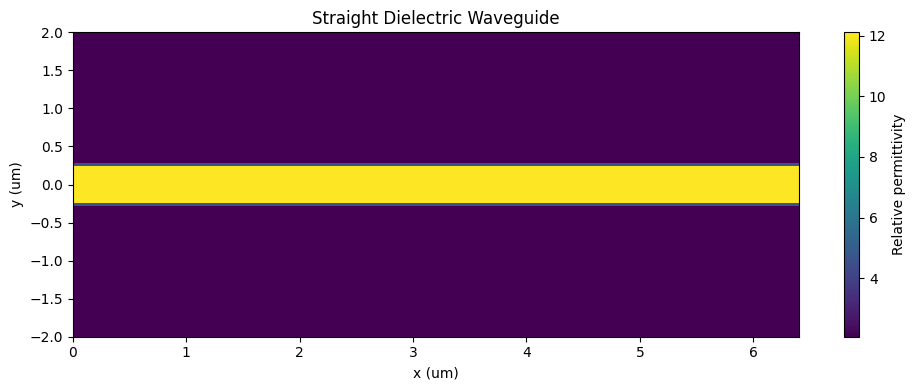

In [3]:
# Transverse coordinates
y = (
    np.arange(ny) - (ny - 1)/2
) * dy

# Subpixel-averaged permittivity
eps_y = subpixel_permittivity(
    y,
    dy,
    width,
    n_core,
    n_clad
)

# Extend along x
eps_r = np.tile(
    eps_y,
    (nx, 1)
)

plt.figure(figsize=(10, 4))

plt.imshow(
    eps_r.T,
    origin="lower",
    extent=[
        0, nx*dx,
        y[0]-dy/2,
        y[-1]+dy/2
    ],
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Relative permittivity")
plt.xlabel("x (um)")
plt.ylabel("y (um)")
plt.title("Straight Dielectric Waveguide")

plt.tight_layout()
plt.show()

In [4]:
def solve_fundamental_mode(eps_y, dy, k0):

    ny = len(eps_y)

    Dyy = sp.diags(
        [
            np.ones(ny-1),
            -2*np.ones(ny),
            np.ones(ny-1)
        ],
        [-1, 0, 1],
        shape=(ny, ny),
        format="csr"
    ) / dy**2

    H = (
        Dyy
        + k0**2 * sp.diags(
            eps_y,
            format="csr"
        )
    )

    eigenvalues, eigenvectors = spla.eigsh(
        H,
        k=1,
        which="LA"
    )

    beta = np.sqrt(eigenvalues[0])

    psi = eigenvectors[:, 0]

    # Normalize transverse mode
    psi = psi / np.sqrt(
        np.sum(np.abs(psi)**2) * dy
    )

    return beta, psi


beta, psi = solve_fundamental_mode(
    eps_y, dy, k0
)

neff = beta / k0

print("Effective index:", neff)
print("Propagation constant:", beta)

Effective index: 3.275099554641766
Propagation constant: 13.276166065339066


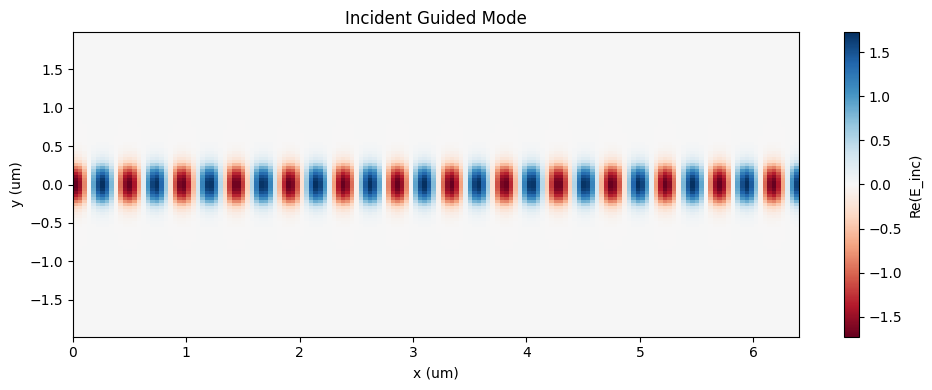

In [5]:
x = np.arange(nx) * dx

E_inc = (
    np.exp(1j * beta * x[:, None])
    * psi[None, :]
)

plt.figure(figsize=(10, 4))

plt.imshow(
    np.real(E_inc).T,
    origin="lower",
    extent=[0, nx*dx, y[0], y[-1]],
    aspect="auto",
    cmap="RdBu"
)

plt.colorbar(label="Re(E_inc)")
plt.xlabel("x (um)")
plt.ylabel("y (um)")
plt.title("Incident Guided Mode")

plt.tight_layout()
plt.show()

In [6]:
if beta * dx / 2 >= 1:
    raise ValueError("Grid is too coarse for this mode")

kx = (
    2 / dx
    * np.arcsin(beta * dx / 2)
)

E_inc = (
    np.exp(1j * kx * x[:, None])
    * psi[None, :]
)

print("Continuous beta:", beta)
print("Discrete kx:", kx)

Continuous beta: 13.276166065339066
Discrete kx: 13.437334369973533


In [7]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.sparse as sp
import scipy.sparse.linalg as spla

# Physical parameters, in micrometers
wavelength = 1.55
k0 = 2 * np.pi / wavelength

# Grid
nx = 100
ny = 100

dx = 0.05
dy = 0.05

# Uniform dielectric
eps_r = np.ones((nx, ny)) * 2.25

# PML thickness in grid cells
npml = 12

print("Grid:", nx, "x", ny)
print("Unknowns:", nx * ny)
print("PML thickness:", npml, "cells")

Grid: 100 x 100
Unknowns: 10000
PML thickness: 12 cells


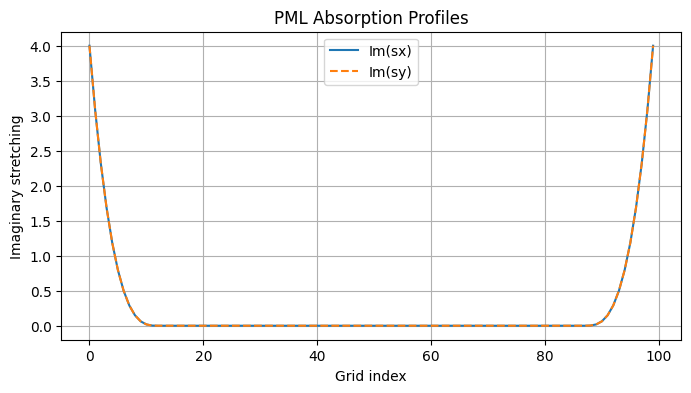

In [8]:
def pml_stretch(n, npml, alpha_max=4.0, order=3):
    """
    Dimensionless complex stretching profile.

    e^(-i omega t) time convention.
    """
    if not (0 < npml < n // 2):
        raise ValueError("npml must be positive and less than n//2")

    s = np.ones(n, dtype=complex)

    for i in range(n):

        if i < npml:
            depth = (npml - i) / npml

        elif i >= n - npml:
            depth = (i - (n - npml - 1)) / npml

        else:
            depth = 0.0

        s[i] = 1 + 1j * alpha_max * depth**order

    return s


sx = pml_stretch(nx, npml)
sy = pml_stretch(ny, npml)

plt.figure(figsize=(8, 4))

plt.plot(np.imag(sx), label="Im(sx)")
plt.plot(np.imag(sy), "--", label="Im(sy)")

plt.xlabel("Grid index")
plt.ylabel("Imaginary stretching")
plt.title("PML Absorption Profiles")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
def build_pml_operator(eps_r, dx, dy, k0, sx, sy):

    nx, ny = eps_r.shape

    # Stretching coefficients at grid points
    SX = sx[:, None]
    SY = sy[None, :]

    ax = np.broadcast_to(SY / SX, (nx, ny))
    ay = np.broadcast_to(SX / SY, (nx, ny))

    mass = eps_r * SX * SY

    # Interface coefficients
    ax_plus = 0.5 * (ax[:-1, :] + ax[1:, :])
    ay_plus = 0.5 * (ay[:, :-1] + ay[:, 1:])

    rows = []
    cols = []
    data = []

    def index(i, j):
        return i * ny + j

    for i in range(nx):
        for j in range(ny):

            p = index(i, j)

            diagonal = k0**2 * mass[i, j]

            # x+ neighbor
            if i < nx - 1:
                a = ax_plus[i, j] / dx**2

                rows.append(p)
                cols.append(index(i + 1, j))
                data.append(a)

                diagonal -= a

            else:
                diagonal -= ax[i, j] / dx**2

            # x- neighbor
            if i > 0:
                a = ax_plus[i - 1, j] / dx**2

                rows.append(p)
                cols.append(index(i - 1, j))
                data.append(a)

                diagonal -= a

            else:
                diagonal -= ax[i, j] / dx**2

            # y+ neighbor
            if j < ny - 1:
                a = ay_plus[i, j] / dy**2

                rows.append(p)
                cols.append(index(i, j + 1))
                data.append(a)

                diagonal -= a

            else:
                diagonal -= ay[i, j] / dy**2

            # y- neighbor
            if j > 0:
                a = ay_plus[i, j - 1] / dy**2

                rows.append(p)
                cols.append(index(i, j - 1))
                data.append(a)

                diagonal -= a

            else:
                diagonal -= ay[i, j] / dy**2

            rows.append(p)
            cols.append(p)
            data.append(diagonal)

    A = sp.coo_matrix(
        (data, (rows, cols)),
        shape=(nx * ny, nx * ny)
    ).tocsr()

    return A

In [10]:
# Construct PML operator
A_pml = build_pml_operator(
    eps_r, dx, dy, k0, sx, sy
)

# Point source
source = np.zeros((nx, ny), dtype=complex)
source[nx // 2, ny // 2] = 1.0

# Solve
E_pml = spla.spsolve(
    A_pml,
    source.ravel()
)

E_pml = E_pml.reshape(nx, ny)

# Residual
residual = np.linalg.norm(
    A_pml @ E_pml.ravel() - source.ravel()
) / np.linalg.norm(source.ravel())

print("PML system relative residual:", residual)

PML system relative residual: 5.199055826712704e-15


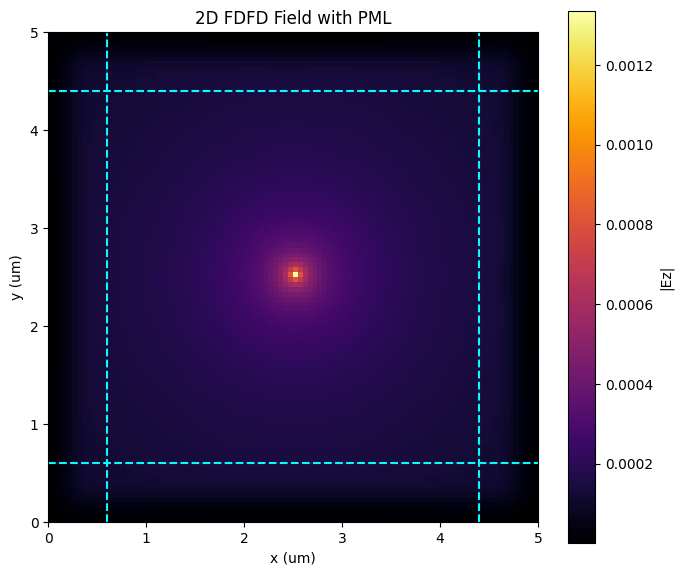

In [11]:
plt.figure(figsize=(7, 6))

plt.imshow(
    np.abs(E_pml).T,
    origin="lower",
    extent=[0, nx*dx, 0, ny*dy],
    cmap="inferno",
    aspect="equal"
)

plt.colorbar(label="|Ez|")

# PML boundaries
plt.axvline(npml*dx, color="cyan", linestyle="--")
plt.axvline((nx-npml)*dx, color="cyan", linestyle="--")

plt.axhline(npml*dy, color="cyan", linestyle="--")
plt.axhline((ny-npml)*dy, color="cyan", linestyle="--")

plt.xlabel("x (um)")
plt.ylabel("y (um)")

plt.title("2D FDFD Field with PML")

plt.tight_layout()
plt.show()

In [12]:
# --------------------------------
# Simulation without PML
# --------------------------------

sx_none = np.ones(nx, dtype=complex)
sy_none = np.ones(ny, dtype=complex)

A_none = build_pml_operator(
    eps_r, dx, dy, k0,
    sx_none, sy_none
)

E_none = spla.spsolve(
    A_none, source.ravel()
).reshape(nx, ny)


# --------------------------------
# Larger reference simulation
# --------------------------------

n_ref = 160
npml_ref = 16

eps_ref = np.ones((n_ref, n_ref)) * 2.25

sx_ref = pml_stretch(n_ref, npml_ref)
sy_ref = pml_stretch(n_ref, npml_ref)

A_ref = build_pml_operator(
    eps_ref,
    dx,
    dy,
    k0,
    sx_ref,
    sy_ref
)

source_ref = np.zeros(
    (n_ref, n_ref),
    dtype=complex
)

source_ref[n_ref//2, n_ref//2] = 1.0

E_ref = spla.spsolve(
    A_ref,
    source_ref.ravel()
).reshape(n_ref, n_ref)


# --------------------------------
# Extract matching physical region
# --------------------------------

# Compare a central 60x60 region
# entirely inside the non-PML
# portion of the smaller simulation.

half = 30

small_slice = slice(
    nx//2-half,
    nx//2+half
)

ref_slice = slice(
    n_ref//2-half,
    n_ref//2+half
)

E_reference_crop = E_ref[
    ref_slice,
    ref_slice
]

E_pml_crop = E_pml[
    small_slice,
    small_slice
]

E_none_crop = E_none[
    small_slice,
    small_slice
]


# --------------------------------
# Relative errors
# --------------------------------

def relative_error(E_test, E_reference):

    return (
        np.linalg.norm(E_test - E_reference)
        / np.linalg.norm(E_reference)
    )


error_pml = relative_error(
    E_pml_crop,
    E_reference_crop
)

error_none = relative_error(
    E_none_crop,
    E_reference_crop
)

print("Error without PML:", error_none)
print("Error with PML:", error_pml)

print(
    "Improvement factor:",
    error_none / error_pml
)

Error without PML: 1.4741232202625956
Error with PML: 0.007068367430136965
Improvement factor: 208.5521493941397


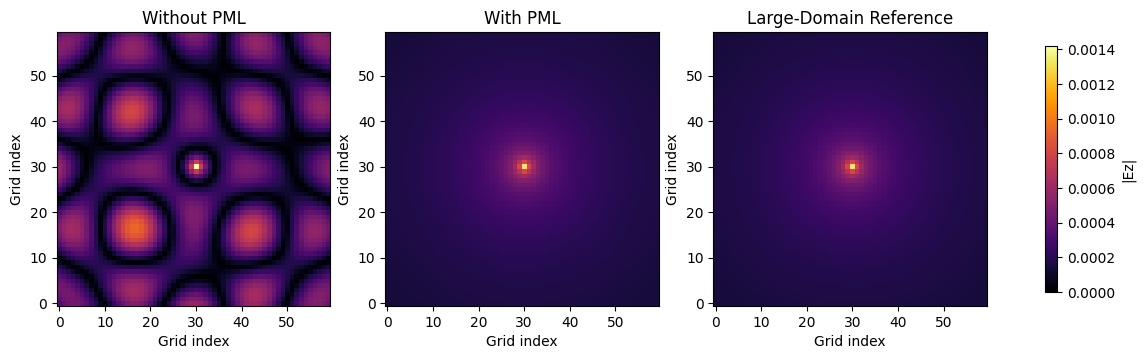

In [13]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

fields = [
    np.abs(E_none_crop),
    np.abs(E_pml_crop),
    np.abs(E_reference_crop)
]

titles = [
    "Without PML",
    "With PML",
    "Large-Domain Reference"
]

vmax = max(np.max(f) for f in fields)

for ax, field, title in zip(
    axes, fields, titles
):

    im = ax.imshow(
        field.T,
        origin="lower",
        cmap="inferno",
        vmin=0,
        vmax=vmax
    )

    ax.set_title(title)
    ax.set_xlabel("Grid index")
    ax.set_ylabel("Grid index")

fig.colorbar(
    im,
    ax=axes,
    label="|Ez|",
    shrink=0.8
)

plt.show()

PML= 6, Grid=88x88, Error=2.233957e-02
PML= 8, Grid=92x92, Error=1.309399e-02
PML=10, Grid=96x96, Error=9.115659e-03
PML=12, Grid=100x100, Error=7.068367e-03
PML=16, Grid=108x108, Error=4.591050e-03
PML=20, Grid=116x116, Error=2.848191e-03


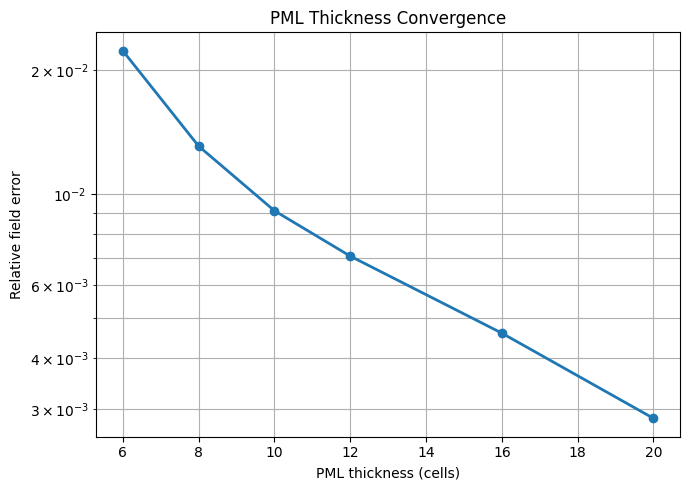

In [14]:
# --------------------------------------
# PML thickness convergence experiment
# --------------------------------------

pml_thicknesses = [6, 8, 10, 12, 16, 20]

physical_size = 76

errors = []
unknowns = []

# Reference field from Cell 6
# E_reference_crop is 60 x 60

for thickness in pml_thicknesses:

    n = physical_size + 2 * thickness

    eps_test = np.ones((n, n)) * 2.25

    sx_test = pml_stretch(
        n, thickness,
        alpha_max=4.0,
        order=3
    )

    sy_test = pml_stretch(
        n, thickness,
        alpha_max=4.0,
        order=3
    )

    A_test = build_pml_operator(
        eps_test,
        dx,
        dy,
        k0,
        sx_test,
        sy_test
    )

    source_test = np.zeros(
        (n, n),
        dtype=complex
    )

    source_test[n//2, n//2] = 1.0

    E_test = spla.spsolve(
        A_test,
        source_test.ravel()
    ).reshape(n, n)

    # Extract central 60 x 60 region
    half = 30

    crop = slice(
        n//2-half,
        n//2+half
    )

    E_test_crop = E_test[crop, crop]

    error = relative_error(
        E_test_crop,
        E_reference_crop
    )

    errors.append(error)
    unknowns.append(n*n)

    print(
        f"PML={thickness:2d}, "
        f"Grid={n}x{n}, "
        f"Error={error:.6e}"
    )


# --------------------------------------
# Plot convergence
# --------------------------------------

plt.figure(figsize=(7, 5))

plt.semilogy(
    pml_thicknesses,
    errors,
    "o-",
    linewidth=2
)

plt.xlabel("PML thickness (cells)")
plt.ylabel("Relative field error")
plt.title("PML Thickness Convergence")

plt.grid(True, which="both")
plt.tight_layout()
plt.show()

In [15]:
# Reference-domain convergence test

reference_configs = [
    (160, 16),
    (200, 20),
    (240, 24)
]

reference_fields = []

for n, thickness in reference_configs:

    eps_test = np.ones((n, n)) * 2.25

    sx_test = pml_stretch(
        n, thickness,
        alpha_max=4.0,
        order=3
    )

    sy_test = pml_stretch(
        n, thickness,
        alpha_max=4.0,
        order=3
    )

    A_test = build_pml_operator(
        eps_test,
        dx,
        dy,
        k0,
        sx_test,
        sy_test
    )

    source_test = np.zeros(
        (n, n),
        dtype=complex
    )

    source_test[n//2, n//2] = 1.0

    E_test = spla.spsolve(
        A_test,
        source_test.ravel()
    ).reshape(n, n)

    # Extract central 60x60 region
    half = 30

    crop = slice(
        n//2-half,
        n//2+half
    )

    reference_fields.append(
        E_test[crop, crop]
    )

    print(f"Completed {n}x{n} reference")


# Compare consecutive references

for i in range(len(reference_fields) - 1):

    error = relative_error(
        reference_fields[i],
        reference_fields[i + 1]
    )

    print(
        f"{reference_configs[i][0]} vs "
        f"{reference_configs[i+1][0]}: "
        f"relative difference = {error:.6e}"
    )

Completed 160x160 reference
Completed 200x200 reference
Completed 240x240 reference
160 vs 200: relative difference = 2.418909e-03
200 vs 240: relative difference = 9.466619e-04


In [16]:
sx = pml_stretch(
    nx,
    npml,
    alpha_max=4.0,
    order=3
)

sy = pml_stretch(
    ny,
    npml,
    alpha_max=4.0,
    order=3
)

A = build_pml_operator(
    eps_r,
    dx,
    dy,
    k0,
    sx,
    sy
)

print("Matrix shape:", A.shape)
print("Nonzero entries:", A.nnz)

Matrix shape: (10000, 10000)
Nonzero entries: 49600


Relative residual: 1.3690672013379925e-14


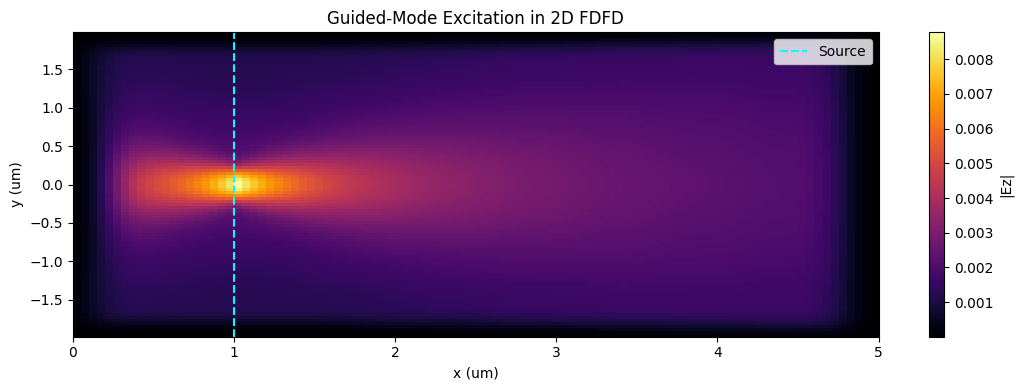

In [17]:
# Define source location
source_index = 20

# Construct the excitation vector b
b_2d = np.zeros((nx, ny), dtype=complex)
b_2d[source_index, :] = psi
b = b_2d.ravel()

# Solve the system
E_flat = spla.spsolve(A, b)
E = E_flat.reshape(nx, ny)

residual = (
    np.linalg.norm(A @ E_flat - b)
    / np.linalg.norm(b)
)

print("Relative residual:", residual)

plt.figure(figsize=(11, 4))

plt.imshow(
    np.abs(E).T,
    origin="lower",
    extent=[0, nx*dx, y[0], y[-1]],
    aspect="auto",
    cmap="inferno"
)

plt.axvline(
    source_index * dx,
    color="cyan",
    linestyle="--",
    label="Source"
)

plt.colorbar(label="|Ez|")

plt.xlabel("x (um)")
plt.ylabel("y (um)")
plt.title("Guided-Mode Excitation in 2D FDFD")

plt.legend()
plt.tight_layout()
plt.show()

In [18]:
def modal_overlap(E_slice, psi, dy):
    return np.vdot(psi, E_slice) * dy


def directional_amplitudes(
    E, psi, dy, kx, dx, i
):
    """
    Extract forward/backward amplitudes
    at reference plane x_i using two
    adjacent cross sections.
    """

    c0 = modal_overlap(E[i, :], psi, dy)
    c1 = modal_overlap(E[i+1, :], psi, dy)

    phase = np.exp(1j * kx * dx)

    denominator = phase - 1 / phase

    a_plus = (
        c1 - c0 / phase
    ) / denominator

    a_minus = c0 - a_plus

    return a_plus, a_minus


# E has shape (nx, ny) where nx = 100. Let's use indices inside the grid.
input_index = 45
output_index = 80

a_in_plus, a_in_minus = directional_amplitudes(
    E, psi, dy, kx, dx, input_index
)

a_out_plus, a_out_minus = directional_amplitudes(
    E, psi, dy, kx, dx, output_index
)

print("Input forward amplitude:", abs(a_in_plus))
print("Input backward amplitude:", abs(a_in_minus))

print("Output forward amplitude:", abs(a_out_plus))
print("Output backward amplitude:", abs(a_out_minus))

Input forward amplitude: 0.0024538094955082967
Input backward amplitude: 0.0009700943596944665
Output forward amplitude: 0.001675862507199259
Output backward amplitude: 0.0006626707762766281


In [19]:
T = (
    abs(a_out_plus)**2
    / abs(a_in_plus)**2
)

R_local = (
    abs(a_in_minus)**2
    / abs(a_in_plus)**2
)

print("Transmission:", T)
print("Transmission (%):", 100*T)

print("Local backward/forward ratio:", R_local)

print("Power balance indicator:", T + R_local)

Transmission: 0.4664392457664957
Transmission (%): 46.64392457664957
Local backward/forward ratio: 0.15629542782730577
Power balance indicator: 0.6227346735938015


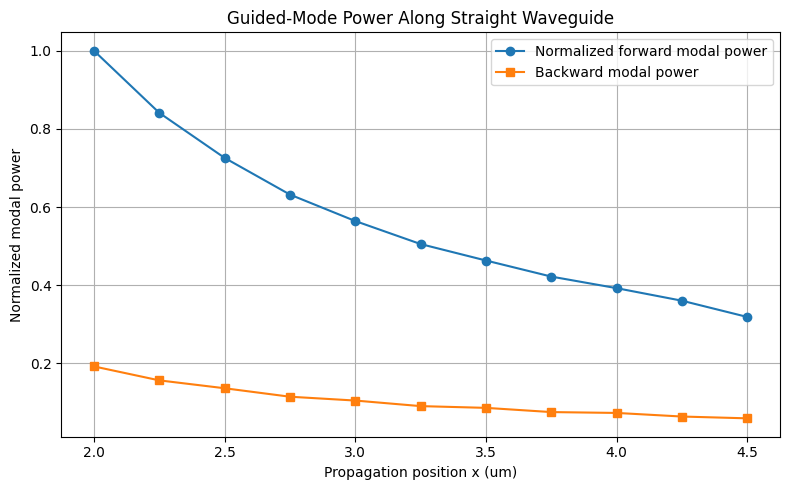

In [20]:
positions = np.arange(40, 95, 5)

forward_power = []
backward_power = []

for i in positions:

    ap, am = directional_amplitudes(
        E, psi, dy, kx, dx, i
    )

    forward_power.append(abs(ap)**2)
    backward_power.append(abs(am)**2)

forward_power = np.array(forward_power)
backward_power = np.array(backward_power)

# Normalize to first measurement
forward_power /= forward_power[0]

plt.figure(figsize=(8, 5))

plt.plot(
    positions * dx,
    forward_power,
    "o-",
    label="Normalized forward modal power"
)

plt.plot(
    positions * dx,
    backward_power / abs(a_in_plus)**2,
    "s-",
    label="Backward modal power"
)

plt.xlabel("Propagation position x (um)")
plt.ylabel("Normalized modal power")

plt.title("Guided-Mode Power Along Straight Waveguide")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
# ==========================================
# DIAGNOSTIC 1:
# Verify the discrete guided-mode solution
# ==========================================

import numpy as np

# Rebuild the intended waveguide geometry
nx = 160
ny = 100

dx = 0.04
dy = 0.04

x = np.arange(nx) * dx

y = (
    np.arange(ny) - (ny - 1)/2
) * dy

eps_y = subpixel_permittivity(
    y,
    dy,
    width,
    n_core,
    n_clad
)

eps_r = np.tile(eps_y, (nx, 1))

# Recalculate transverse mode
beta, psi = solve_fundamental_mode(
    eps_y,
    dy,
    k0
)

# Discrete longitudinal propagation constant
kx = (
    2 / dx
    * np.arcsin(beta * dx / 2)
)

# Construct exact discrete guided-mode field
E_test = (
    np.exp(1j * kx * x[:, None])
    * psi[None, :]
)

# Build operator without PML
sx_none = np.ones(nx, dtype=complex)
sy_none = np.ones(ny, dtype=complex)

A_none = build_pml_operator(
    eps_r,
    dx,
    dy,
    k0,
    sx_none,
    sy_none
)

# Apply operator
residual_field = (
    A_none @ E_test.ravel()
).reshape(nx, ny)

# Evaluate only the interior x region
# The outer x boundaries impose Dirichlet
# conditions and should be excluded.
interior = slice(10, nx - 10)

relative_mode_residual = (
    np.linalg.norm(residual_field[interior, :])
    / np.linalg.norm(E_test[interior, :])
)

print(
    "Discrete guided-mode residual:",
    relative_mode_residual
)

Discrete guided-mode residual: 2.647398317252998e-12


In [22]:
# ==========================================
# DIAGNOSTIC 2:
# Compare interior PML and ordinary operators
# ==========================================

npml = 12

sx = pml_stretch(
    nx,
    npml,
    alpha_max=4.0,
    order=3
)

sy = pml_stretch(
    ny,
    npml,
    alpha_max=4.0,
    order=3
)

A_pml = build_pml_operator(
    eps_r,
    dx,
    dy,
    k0,
    sx,
    sy
)

# Apply both operators to the same field
r_none = (
    A_none @ E_test.ravel()
).reshape(nx, ny)

r_pml = (
    A_pml @ E_test.ravel()
).reshape(nx, ny)

# Exclude PML and its immediate interfaces
margin = npml + 3

region = (
    slice(margin, nx - margin),
    slice(margin, ny - margin)
)

difference = (
    np.linalg.norm(
        r_pml[region] - r_none[region]
    )
    / np.linalg.norm(E_test[region])
)

print(
    "Interior operator difference:",
    difference
)

Interior operator difference: 0.0


In [23]:
# ==========================================
# DIAGNOSTIC 3:
# Check incident-field consistency
# ==========================================

# Apply PML operator to incident field
incident_residual = (
    A_pml @ E_test.ravel()
).reshape(nx, ny)

# Select physical interior
margin = npml + 3

physical_region = (
    slice(margin, nx - margin),
    slice(margin, ny - margin)
)

relative_incident_residual = (
    np.linalg.norm(
        incident_residual[physical_region]
    )
    / np.linalg.norm(E_test[physical_region])
)

print(
    "Incident-field interior residual:",
    relative_incident_residual
)

Incident-field interior residual: 2.701285878595431e-12


In [24]:
nx = 160
ny = 100

In [25]:
nx = 100
ny = 100

In [26]:
# ==========================================
# LOCALIZED MODAL SOURCE
# ==========================================

nx = 160
ny = 100

source_index = 25

# Incident field from diagnostic tests
# E_test.shape = (160, 100)

b_local = np.zeros(
    (nx, ny),
    dtype=complex
)

# Coupling across source interface
b_local[source_index - 1, :] = (
    E_test[source_index, :] / dx**2
)

b_local[source_index, :] = (
    -E_test[source_index - 1, :] / dx**2
)

print("Localized source norm:",
      np.linalg.norm(b_local))

# Verify source support
print(
    "Nonzero source columns:",
    np.where(
        np.any(np.abs(b_local) > 1e-12, axis=1)
    )[0]
)

Localized source norm: 4419.4173824159225
Nonzero source columns: [24 25]


Relative solver residual: 1.2205690358072701e-14


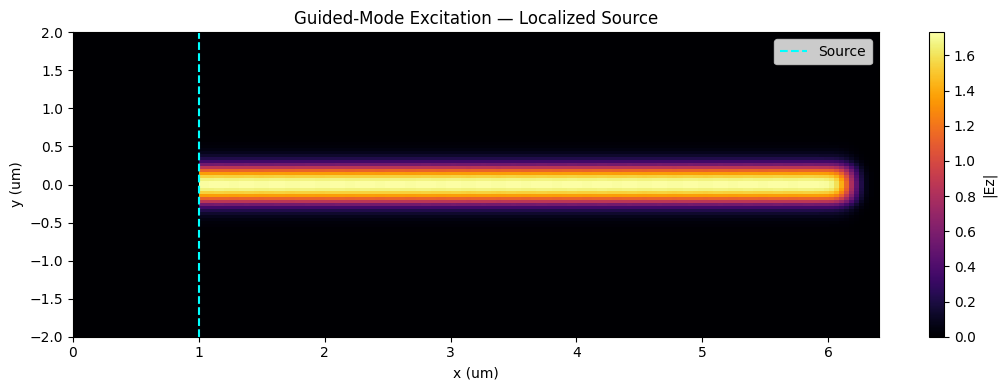

In [27]:
# ==========================================
# FORWARD SIMULATION
# ==========================================

E_local_flat = spla.spsolve(
    A_pml,
    b_local.ravel()
)

E_local = E_local_flat.reshape(
    nx, ny
)

residual = (
    np.linalg.norm(
        A_pml @ E_local_flat - b_local.ravel()
    )
    / np.linalg.norm(b_local.ravel())
)

print("Relative solver residual:", residual)

plt.figure(figsize=(11, 4))

plt.imshow(
    np.abs(E_local).T,
    origin="lower",
    extent=[
        0,
        nx*dx,
        y[0]-dy/2,
        y[-1]+dy/2
    ],
    aspect="auto",
    cmap="inferno"
)

plt.axvline(
    source_index*dx,
    color="cyan",
    linestyle="--",
    label="Source"
)

plt.xlabel("x (um)")
plt.ylabel("y (um)")
plt.title("Guided-Mode Excitation — Localized Source")

plt.colorbar(label="|Ez|")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
input_index = 45
output_index = 125

a_in_plus, a_in_minus = directional_amplitudes(
    E_local,
    psi,
    dy,
    kx,
    dx,
    input_index
)

a_out_plus, a_out_minus = directional_amplitudes(
    E_local,
    psi,
    dy,
    kx,
    dx,
    output_index
)

T = (
    abs(a_out_plus)**2
    / abs(a_in_plus)**2
)

R_local = (
    abs(a_in_minus)**2
    / abs(a_in_plus)**2
)

print("Input forward:", abs(a_in_plus))
print("Input backward:", abs(a_in_minus))

print("Output forward:", abs(a_out_plus))
print("Output backward:", abs(a_out_minus))

print("Transmission:", T)
print("Local backward ratio:", R_local)

Input forward: 0.9999904964989621
Input backward: 0.0030878527582784247
Output forward: 0.9999904964989603
Output backward: 0.0030878527582779264
Transmission: 0.9999999999999964
Local backward ratio: 9.535015888013283e-06


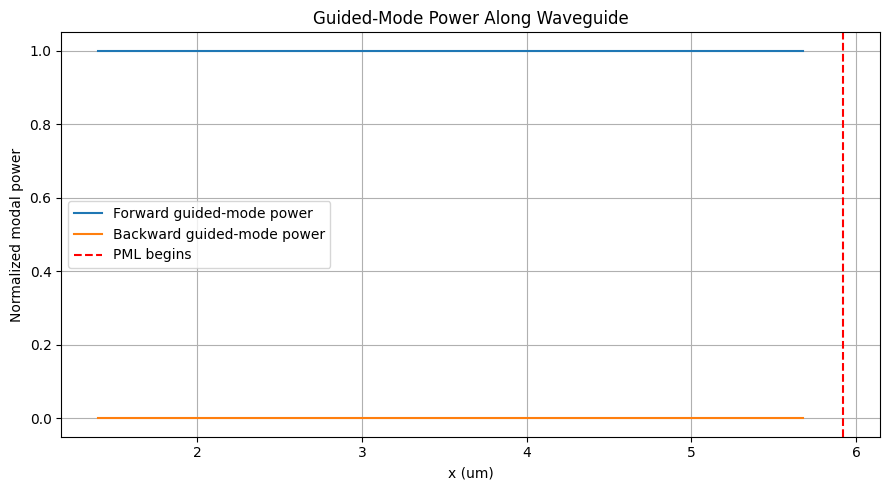

Forward power ratio (last/first): 0.9999999999999967


In [29]:
# ==========================================
# GUIDED-MODE AMPLITUDE PROFILE
# ==========================================

positions = np.arange(
    source_index + 10,
    nx - npml - 5
)

forward = []
backward = []

for i in positions:

    ap, am = directional_amplitudes(
        E_local,
        psi,
        dy,
        kx,
        dx,
        i
    )

    forward.append(abs(ap)**2)
    backward.append(abs(am)**2)

forward = np.array(forward)
backward = np.array(backward)

# Normalize using first forward power
reference_power = forward[0]

forward /= reference_power
backward /= reference_power

plt.figure(figsize=(9, 5))

plt.plot(
    positions*dx,
    forward,
    label="Forward guided-mode power"
)

plt.plot(
    positions*dx,
    backward,
    label="Backward guided-mode power"
)

plt.axvline(
    (nx-npml)*dx,
    color="red",
    linestyle="--",
    label="PML begins"
)

plt.xlabel("x (um)")
plt.ylabel("Normalized modal power")

plt.title("Guided-Mode Power Along Waveguide")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(
    "Forward power ratio (last/first):",
    forward[-1] / forward[0]
)

In [30]:
sx = pml_stretch(
    nx,
    npml,
    alpha_max=4.0,
    order=3
)

sy = np.ones(
    ny,
    dtype=complex
)

A_xpml = build_pml_operator(
    eps_r,
    dx,
    dy,
    k0,
    sx,
    sy
)

In [31]:
# ==========================================
# SOURCE EQUIVALENCE VERIFICATION
# ==========================================

assert A_pml.shape == (nx * ny, nx * ny)

mask = np.zeros((nx, ny))
mask[source_index:, :] = 1.0

# Original commutator source
b_commutator = (
    A_pml @ (mask * E_test).ravel()
    - mask.ravel() * (A_pml @ E_test.ravel())
)

# Localized source
b_local_flat = b_local.ravel()

source_difference = (
    np.linalg.norm(b_commutator - b_local_flat)
    / np.linalg.norm(b_local_flat)
)

print("Source equivalence error:", source_difference)

Source equivalence error: 4.936194512741947e-09
